#**Final SAM**

In [3]:
pip install git+https://github.com/TissueImageAnalytics/tiatoolbox.git@develop

  Cloning https://github.com/TissueImageAnalytics/tiatoolbox.git (to revision develop) to /tmp/pip-req-build-vn3cx4w5
  Running command git clone --filter=blob:none --quiet https://github.com/TissueImageAnalytics/tiatoolbox.git /tmp/pip-req-build-vn3cx4w5
  Resolved https://github.com/TissueImageAnalytics/tiatoolbox.git to commit 6643e7a33929bf53ed488ac5b0acfad063978d01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 11.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 74.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.4/225.4 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.2/210.2 kB 17.0 MB/s eta 0:00:00


In [4]:
pip install patchify

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os
import sys
import numpy as np
import cv2
from pprint import pprint
from matplotlib import pyplot as plt
import numpy as np
import PIL as Img
import tifffile as tiff
from tiatoolbox.wsicore.wsireader import WSIReader
from patchify import patchify

In [6]:
import torch

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
DEVICE

device(type='cuda', index=0)

In [7]:
!nvidia-smi

Wed Jun 26 10:51:05 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.129.03             Driver Version: 535.129.03   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   42C    P8               9W /  70W |      3MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [8]:
# from google.colab import drive
# drive.mount('/content/drive')
kaggle_cam_data = "/kaggle/input/camelyon-17-images"

In [9]:
image_camelyon17_path1 = kaggle_cam_data + "/patient_000_node_0.tif"
image_camelyon17_path2 = kaggle_cam_data + "/patient_000_node_1.tif"

In [10]:
wsi_cam17_1 = WSIReader.open(image_camelyon17_path1)
wsi_cam17_2 = WSIReader.open(image_camelyon17_path2)

In [11]:
info_dict = wsi_cam17_1.info.as_dict()
pprint(info_dict)  # Done

{'axes': 'YXS',
 'file_path': PosixPath('/kaggle/input/camelyon-17-images/patient_000_node_0.tif'),
 'level_count': 9,
 'level_dimensions': ((96651, 197226),
                      (48325, 98613),
                      (24162, 49306),
                      (12081, 24653),
                      (6040, 12326),
                      (3020, 6163),
                      (1510, 3081),
                      (755, 1540),
                      (377, 770)),
 'level_downsamples': [1.0,
                       2.000010346611485,
                       4.000082362460885,
                       8.00016472492177,
                       16.00131624262717,
                       32.00263248525434,
                       64.01045835294724,
                       128.04170035262752,
                       256.2531813014572],
 'mpp': (0.2430938184827319, 0.2430938184827319),
 'objective_power': 40.0,
 'slide_dimensions': (96651, 197226),
 'vendor': 'generic-tiff'}


In [12]:
info_dict = wsi_cam17_2.info.as_dict()
pprint(info_dict)  # Done

{'axes': 'YXS',
 'file_path': PosixPath('/kaggle/input/camelyon-17-images/patient_000_node_1.tif'),
 'level_count': 9,
 'level_dimensions': ((96651, 197226),
                      (48325, 98613),
                      (24162, 49306),
                      (12081, 24653),
                      (6040, 12326),
                      (3020, 6163),
                      (1510, 3081),
                      (755, 1540),
                      (377, 770)),
 'level_downsamples': [1.0,
                       2.000010346611485,
                       4.000082362460885,
                       8.00016472492177,
                       16.00131624262717,
                       32.00263248525434,
                       64.01045835294724,
                       128.04170035262752,
                       256.2531813014572],
 'mpp': (0.2430938184827319, 0.2430938184827319),
 'objective_power': 40.0,
 'slide_dimensions': (96651, 197226),
 'vendor': 'generic-tiff'}


In [13]:
def display_region(wsi, level, title):
    slide_dimensions = wsi.slide_dimensions(level, units="mpp")
#     region = wsi.read_region(location=(0, 0), level=level, size=slide_dimensions)
    region = wsi.read_rect( location=(0,0),size =wsi.info.level_dimensions[level+1],resolution=level,units="mpp")
    region = np.array(region)

    plt.figure(figsize=(10, 10))
    plt.imshow(region)
    plt.title(f'{title}_{region.shape}')
    plt.grid("on")
    plt.axis('off')
    plt.show()

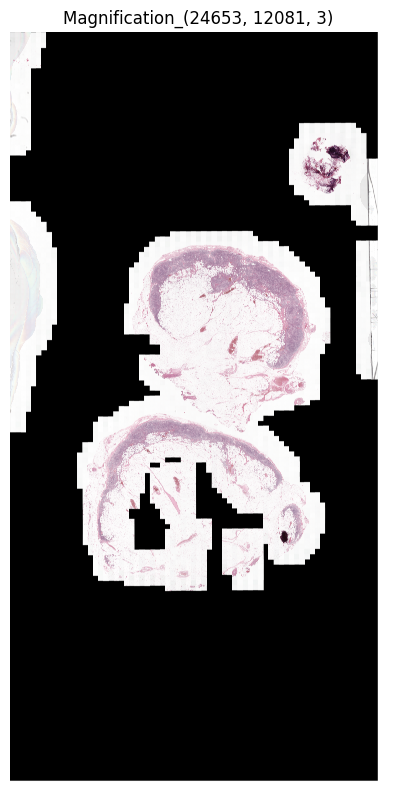

In [12]:
display_region(wsi_cam17_1, level=2, title='Magnification') # Done

In [21]:
def extract_region_and_create_mask(wsi, zoom_level, sthresh=50, sthresh_up=255, mthresh=7, close=1, use_otsu=True, filter_params={'a_t':1000, 'max_n_holes':3, 'a_h':50}):
    # Get dimensions of the WSI at the specified zoom level
    wsi_dimensions = wsi.info.level_dimensions[zoom_level + 1]
    w, h = wsi_dimensions

    # Read the region of the WSI
    large_image = wsi.read_rect(location=(0, 0), size=(w , h), resolution=zoom_level, units="mpp")
    large_image = np.array(large_image)

    # Convert the image to HSV color space
    img_hsv = cv2.cvtColor(large_image, cv2.COLOR_BGR2HSV)

    # Apply median blurring to the saturation channel
    img_med = cv2.medianBlur(img_hsv[:, :, 1], mthresh)

    # Thresholding to create a binary mask
    if use_otsu:
        _, tissue_mask = cv2.threshold(img_med, 0, sthresh_up, cv2.THRESH_OTSU + cv2.THRESH_BINARY)
    else:
        _, tissue_mask = cv2.threshold(img_med, sthresh, sthresh_up, cv2.THRESH_BINARY)

    # Morphological closing to remove small holes
    if close > 0:
        kernel = np.ones((close, close), np.uint8)
        tissue_mask = cv2.morphologyEx(tissue_mask, cv2.MORPH_CLOSE, kernel)

    # Find contours
    contours, hierarchy = cv2.findContours(tissue_mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    hierarchy = np.squeeze(hierarchy, axis=(0,))[:, 2:]

    # Filter contours based on area
    def _filter_contours(contours, hierarchy, filter_params):
        filtered = []
        hierarchy_1 = np.flatnonzero(hierarchy[:, 1] == -1)
        all_holes = []

        for cont_idx in hierarchy_1:
            cont = contours[cont_idx]
            holes = np.flatnonzero(hierarchy[:, 1] == cont_idx)
            a = cv2.contourArea(cont)
            hole_areas = [cv2.contourArea(contours[hole_idx]) for hole_idx in holes]
            a = a - np.array(hole_areas).sum()
            if a == 0: continue
            if a > filter_params['a_t']:
                filtered.append(cont_idx)
                all_holes.append(holes)

        foreground_contours = [contours[cont_idx] for cont_idx in filtered]
        hole_contours = []

        for hole_ids in all_holes:
            unfiltered_holes = [contours[idx] for idx in hole_ids]
            unfiltered_holes = sorted(unfiltered_holes, key=cv2.contourArea, reverse=True)
            unfiltered_holes = unfiltered_holes[:filter_params['max_n_holes']]
            filtered_holes = [hole for hole in unfiltered_holes if cv2.contourArea(hole) > filter_params['a_h']]
            hole_contours.append(filtered_holes)

        return foreground_contours, hole_contours

    foreground_contours, hole_contours = _filter_contours(contours, hierarchy, filter_params)

    # Create a new mask to draw the filled contours
    cleaned_mask = np.zeros_like(tissue_mask)
    cv2.drawContours(cleaned_mask, foreground_contours, -1, (255), thickness=cv2.FILLED)

    # Focus on the central region
#     mask_center = cleaned_mask.shape[0] // 2, cleaned_mask.shape[1] // 2
#     radius = min(cleaned_mask.shape[0], cleaned_mask.shape[1]) // 4
#     central_mask = np.zeros_like(cleaned_mask)
#     cv2.circle(central_mask, mask_center, radius, (255), thickness=cv2.FILLED)
#     central_tissue_mask = cv2.bitwise_and(cleaned_mask, central_mask)

    return large_image, cleaned_mask

In [22]:
large_image, dummy_tissue_mask = extract_region_and_create_mask(wsi_cam17_1, zoom_level=2)

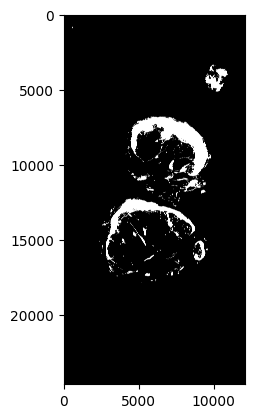

In [23]:
plt.imshow(dummy_tissue_mask,cmap='gray')

In [24]:
def crop_to_patch_size(wsi, zoom_level, patch_size):
    large_image, dummy_tissue_mask = extract_region_and_create_mask(wsi, zoom_level)
    height, width, _ = large_image.shape
    new_height = (height // patch_size) * patch_size
    new_width = (width // patch_size) * patch_size

    large_image_cropped = large_image[:new_height, :new_width, :]
    tissue_mask_cropped = dummy_tissue_mask[:new_height, :new_width]

    return large_image_cropped, tissue_mask_cropped

In [25]:
# large_image_cropped, tissue_mask_cropped = crop_to_patch_size(wsi_cam17_1, 6, patch_size=256)

In [26]:
def count_holes(mask, min_hole_area=50):
    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    # Filter holes by minimum area
    hole_count = sum(1 for cnt in contours if cv2.contourArea(cnt) > min_hole_area)
    return hole_count

In [78]:
patches_dir = 'patches_final'
masks_dir = 'masks'
os.makedirs(patches_dir, exist_ok=True)
os.makedirs(masks_dir, exist_ok=True)

In [83]:
def create_and_store_patches(wsi, wsi_paths, zoom_level, patch_size, step_size, max_holes=1, min_hole_area=0):
    patches_folder_names = []
    masks_folder_names = []

    for wsi_path in wsi_paths:
        wsi = WSIReader.open(wsi_path)
        
        base_name = os.path.basename(wsi_path).split('.')[0]
        folder_suffix = f"{base_name[:3]}{base_name[-10:]}"
        patches_dir = os.path.join('patches_final', folder_suffix)
        masks_dir = os.path.join('masks', folder_suffix)
        os.makedirs(patches_dir, exist_ok=True)
        os.makedirs(masks_dir, exist_ok=True)

        patches_folder_names.append(patches_dir)
        masks_folder_names.append(masks_dir)

        large_image_cropped, tissue_mask_cropped = crop_to_patch_size(wsi, zoom_level, patch_size)

        # Check if large_image_cropped is large enough for the patch size
        if large_image_cropped.shape[0] < patch_size or large_image_cropped.shape[1] < patch_size:
            print(f"Image is too small for the patch size: {patch_size}. Skipping...")
            continue

        patches_img = patchify(large_image_cropped, (patch_size, patch_size, 3), step=step_size)
        patches_mask = patchify(tissue_mask_cropped, (patch_size, patch_size), step=step_size)

        for i in range(patches_img.shape[0]):
            for j in range(patches_img.shape[1]):
                single_patch_img = patches_img[i, j, 0, :, :, :]
                single_patch_mask = patches_mask[i, j, :, :]
                single_patch_mask = single_patch_mask.reshape(patch_size, patch_size, 1)

                # Check the number of holes in the patch
                hole_count = count_holes(single_patch_mask, min_hole_area)
                if np.mean(single_patch_mask) > 200 and hole_count <= max_holes:
                    patch_filename = os.path.join(patches_dir, f'image_{i}_{j}_Z{zoom_level}_P{patch_size}.tif')
                    tiff.imwrite(patch_filename, single_patch_img)

    return patches_folder_names, masks_folder_names

In [84]:
patches_folders, masks_folders = create_and_store_patches([wsi_cam17_1],[image_camelyon17_path1], zoom_level=2, patch_size=256, step_size=256)

In [85]:
def plot_patches_from_folders(patches_root_dir):

    for folder in os.listdir(patches_root_dir):
        patches_dir = os.path.join(patches_root_dir, folder)

        if not os.path.isdir(patches_dir):
            continue

        patch_files = sorted(os.listdir(patches_dir))
        num_rows = max([int(f.split('_')[1]) for f in patch_files]) + 1
        num_cols = max([int(f.split('_')[2].split('.')[0]) for f in patch_files]) + 1


        fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 20))

        for patch_file in patch_files:
            parts = patch_file.split('_')
            row_idx = int(parts[1])
            col_idx = int(parts[2].split('.')[0])

            patch_path = os.path.join(patches_dir, patch_file)
            patch_img = tiff.imread(patch_path)

            axes[row_idx, col_idx].imshow(patch_img)
            axes[row_idx, col_idx].axis('off')
            axes[row_idx, col_idx].set_title(f'Patch {row_idx}_{col_idx}')

        plt.tight_layout()
        plt.grid("off")
        plt.suptitle(f"Patches from {folder}", fontsize=16)
        plt.show()

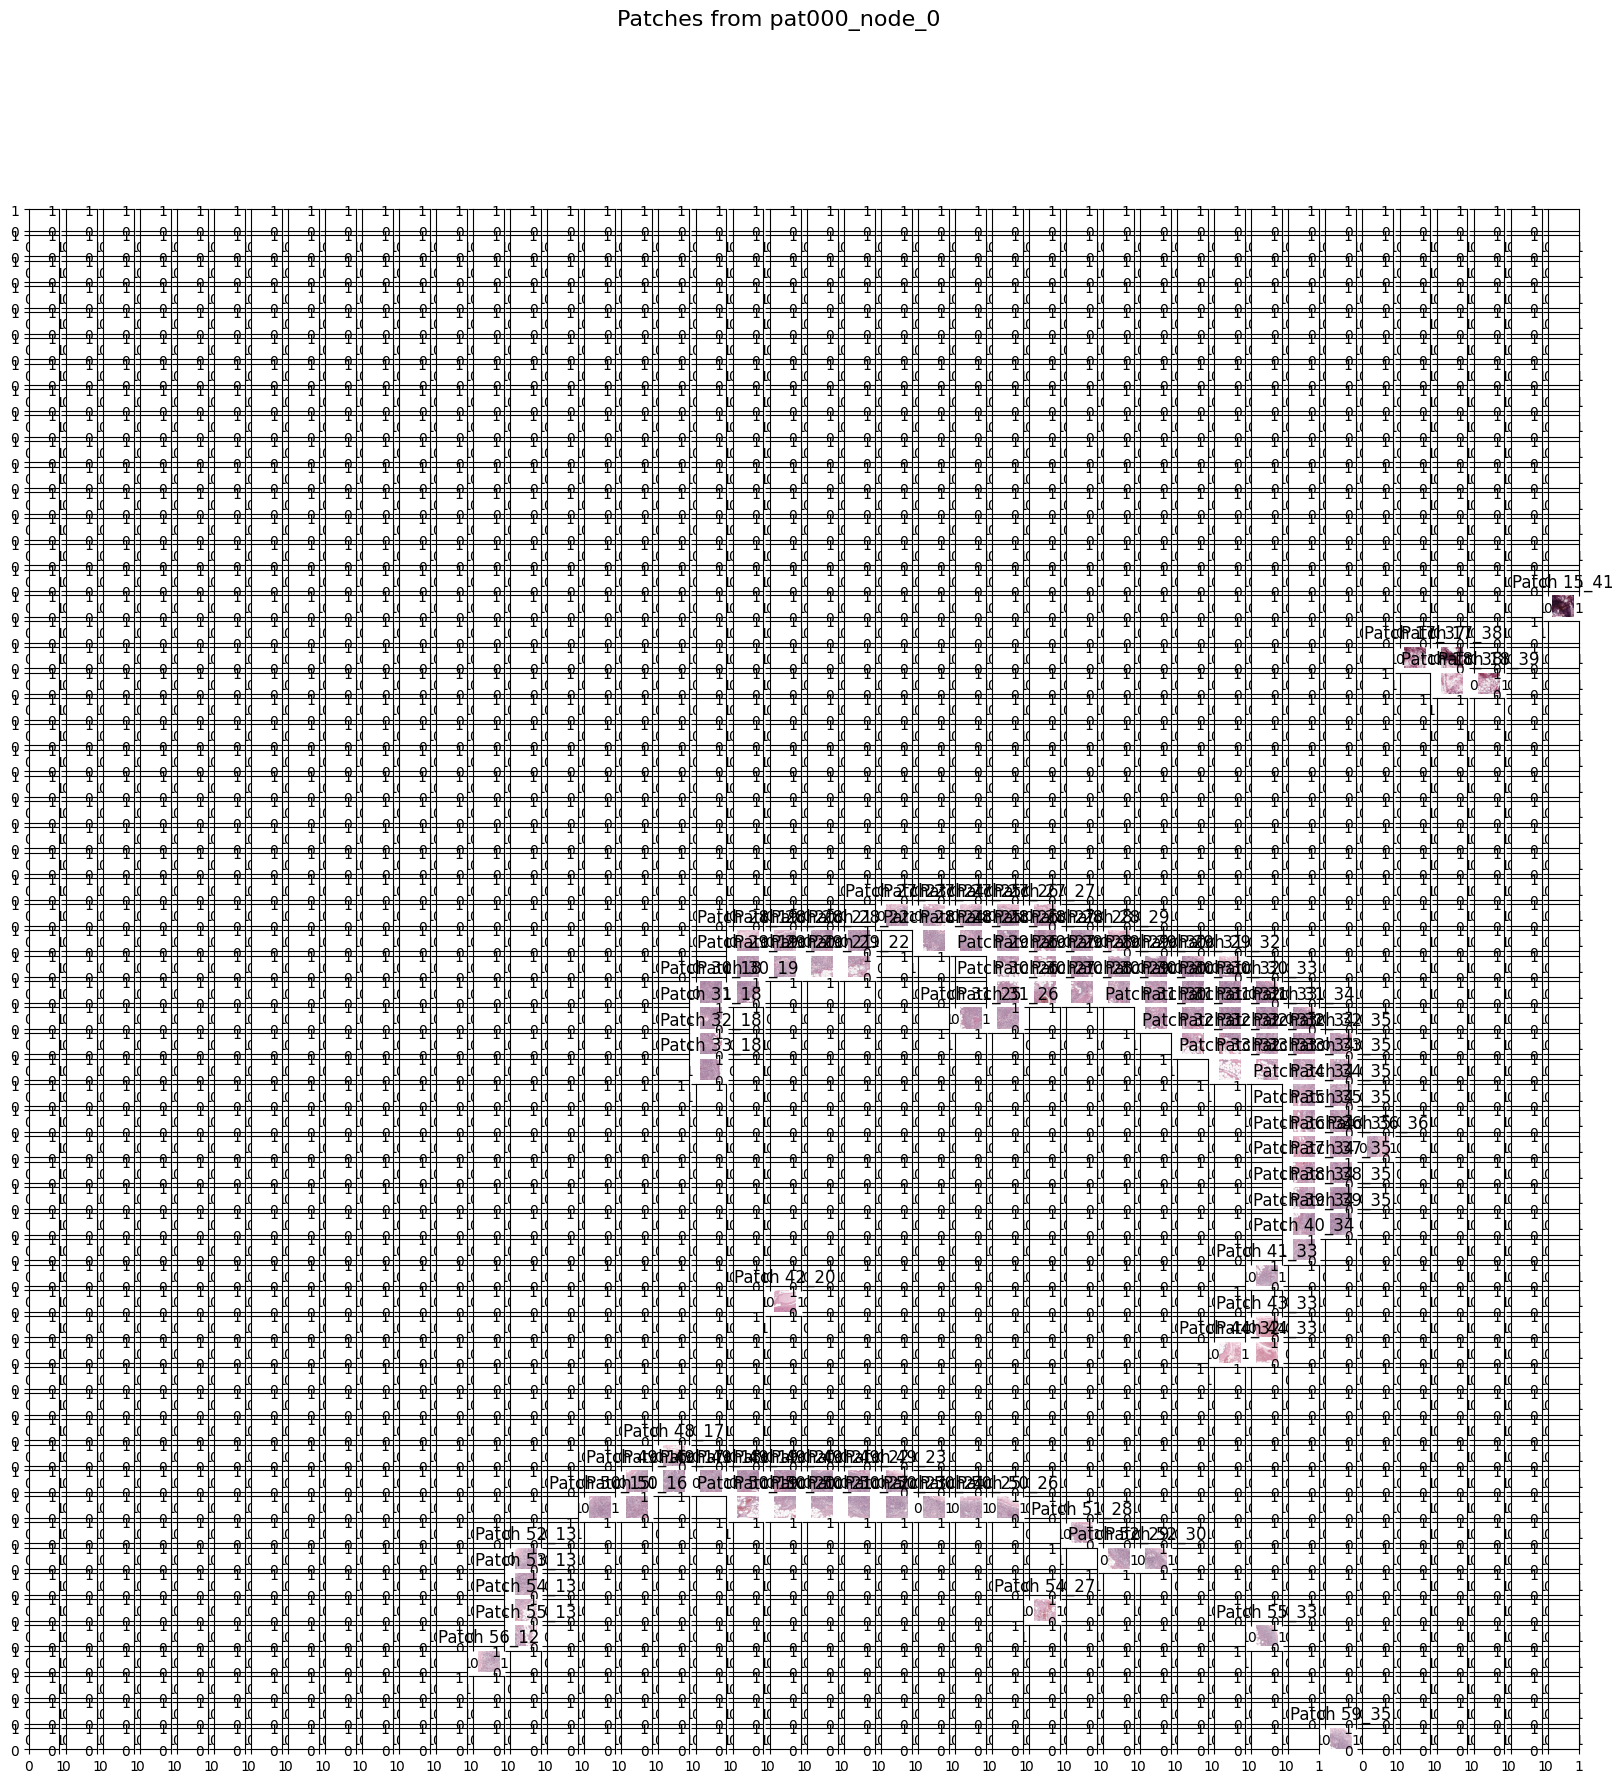

In [86]:
plot_patches_from_folders(patches_dir)

Installation

In [87]:
pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-4byjndqy
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-4byjndqy
  Resolved https://github.com/facebookresearch/segment-anything.git to commit 6fdee8f2727f4506cfbbe553e23b895e27956588
  Preparing metadata (setup.py) ... done
Note: you may need to restart the kernel to use updated packages.


Import SAM Model:

In [88]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

In [89]:
HOME = os.getcwd()
print("HOME:", HOME)

HOME: /kaggle/working


In [90]:
!mkdir -p {HOME}/weights
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth -P {HOME}/weights

In [91]:
sam_checkpoint = os.path.join(HOME, "weights", "sam_vit_h_4b8939.pth")
model_type = "vit_h"
print(sam_checkpoint, "; exist:", os.path.isfile(sam_checkpoint))

/kaggle/working/weights/sam_vit_h_4b8939.pth ; exist: True


In [92]:
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(DEVICE)

Sam(
  (image_encoder): ImageEncoderViT(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 1280, kernel_size=(16, 16), stride=(16, 16))
    )
    (blocks): ModuleList(
      (0-31): 32 x Block(
        (norm1): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1280, out_features=3840, bias=True)
          (proj): Linear(in_features=1280, out_features=1280, bias=True)
        )
        (norm2): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (lin1): Linear(in_features=1280, out_features=5120, bias=True)
          (lin2): Linear(in_features=5120, out_features=1280, bias=True)
          (act): GELU(approximate='none')
        )
      )
    )
    (neck): Sequential(
      (0): Conv2d(1280, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): LayerNorm2d()
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (3): LayerNorm2d

In [93]:
# mask_generator = SamAutomaticMaskGenerator(
#     model=sam,
#     points_per_side=16,
#     pred_iou_thresh=0.86,
#     stability_score_thresh=0.92
# )

Into Procedure:

In [98]:
def show_anns(anns):
    if len(anns) == 0:
        return None

    sorted_anns = sorted(anns, key=lambda x: x['area'], reverse=True)
    height, width = sorted_anns[0]['segmentation'].shape
    img = np.ones((height, width, 3))

    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.random.random(3)
        img[m] = color_mask

    return img

In [99]:
def create_and_store_masks(patches_root_dir, masks_root_dir, prompt_points):
    for folder in os.listdir(patches_root_dir):
        patches_dir = os.path.join(patches_root_dir, folder)
        if not os.path.isdir(patches_dir):
            continue

        masks_dir = os.path.join(masks_root_dir, folder)
        os.makedirs(masks_dir, exist_ok=True)

        patch_files = sorted(os.listdir(patches_dir))

        for patch_file in patch_files:
            patch_path = os.path.join(patches_dir, patch_file)
            patch_img = tiff.imread(patch_path)
            if len(patch_img.shape) == 2:
                patch_img = cv2.cvtColor(patch_img, cv2.COLOR_GRAY2RGB)
            elif patch_img.shape[2] == 4:  # If there's an alpha channel, remove it
                patch_img = patch_img[:, :, :3]

            # Create masks
            mask = mask_generator.generate(patch_img)
            final_mask = show_anns(mask)
            mask_filename = os.path.join(masks_dir, f'mask_{patch_file.split(".")[0]}_pp{prompt_points}.tif')
            tiff.imwrite(mask_filename, (final_mask * 255).astype(np.uint8))

        print(f"Masks created and saved successfully....{masks_dir}")

In [100]:
# patches_root_dir = 'patches'
# masks_root_dir = 'masks'
# create_and_store_masks(patches_root_dir, masks_root_dir)

In [101]:
def plot_patches_with_masks(patches_root_dir, masks_root_dir, save_dir):
    patch_files = [f for f in os.listdir(patches_root_dir) if f.endswith('.tif')]
    mask_files = [f for f in os.listdir(masks_root_dir) if f.endswith('.tif')]

    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    for patch_file in patch_files:
        patch_path = os.path.join(patches_root_dir, patch_file)
        patch_img = tiff.imread(patch_path)

        patch_base_name = patch_file.split('.')[0]

        # Extract parameters from the patch file name
        match = re.match(r'image_(\d+)_(\d+)_Z(\d+)_P(\d+)', patch_base_name)
        if match:
            row_idx, col_idx, zoom_level, patch_size = match.groups()
        else:
            continue

        matched_mask_files = []
        for mask_file in mask_files:
            mask_base_name = mask_file.split('.')[0]

            # Match the masks using the extracted parameters
            mask_match = re.match(rf'mask_image_{row_idx}_{col_idx}_Z{zoom_level}_P{patch_size}_pp(\d+)', mask_base_name)
            if mask_match:
                matched_mask_files.append(mask_file)

        masks = [tiff.imread(os.path.join(masks_root_dir, mask_file)) for mask_file in matched_mask_files]

        # Overlay and display the masks on the normal image
        for i, mask in enumerate(masks):
            overlay_image = cv2.addWeighted(patch_img, 0.7, mask, 0.3, 0)

            plt.figure(figsize=(15, 5))
            plt.subplot(1, 3, 1)
            plt.imshow(patch_img)
            plt.title(f"Raw Patch: {patch_file}")

            plt.subplot(1, 3, 2)
            plt.imshow(mask, cmap='gray')
            plt.title(f"Segmentation Mask: {matched_mask_files[i]}")

            plt.subplot(1, 3, 3)
            plt.imshow(overlay_image)
            plt.title("Overlay")

            # Save the final image to the specified directory
            save_path = os.path.join(save_dir, f'overlay_{patch_base_name}_{i}.png')
            plt.savefig(save_path)
            plt.close()

#             plt.show()

In [102]:
# patches_root_dir = 'patches/pat000_node_0'
# masks_root_dir = 'masks/pat000_node_0'
# plot_patches_with_masks(patches_root_dir, masks_root_dir)

In [103]:
# Params
step_size_listy = 256
zoom_levels_listy = [2]
patch_sizes_listy = [256,512, 768,1024]
prompt_points_listy = [8,16,32]

In [104]:
import itertools
permutations = list(itertools.product(zoom_levels_listy, patch_sizes_listy, prompt_points_listy))

In [105]:
wsi_cam17_1 = WSIReader.open(image_camelyon17_path1)
wsi_cam17_2 = WSIReader.open(image_camelyon17_path2)

In [106]:
patches_root_dir = 'patches_final'
masks_root_dir = 'masks'

In [107]:
for zoom_level, patch_size, prompt_points in permutations:
    print(f"Processing with zoom_level={zoom_level}, patch_size={patch_size}, prompt_points={prompt_points}")
#     patches_folders, masks_folders = create_and_store_patches([wsi_cam17_1], [image_camelyon17_path1], zoom_level, patch_size, step_size_listy)
    patches_folders, masks_folders = create_and_store_patches([wsi_cam17_1],[image_camelyon17_path1], zoom_level=zoom_level, patch_size=patch_size, step_size=step_size_listy)

    mask_generator = SamAutomaticMaskGenerator(
          model=sam,
          points_per_side=prompt_points,
          pred_iou_thresh=0.86,
          stability_score_thresh=0.92
    )
    create_and_store_masks('patches_final', 'masks',prompt_points)
print("Processing complete.")

Processing with zoom_level=2, patch_size=256, prompt_points=8
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=256, prompt_points=16
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=256, prompt_points=32
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=512, prompt_points=8
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=512, prompt_points=16
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=512, prompt_points=32
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=768, prompt_points=8
Masks created and saved successfully....masks/pat000_node_0
Processing with zoom_level=2, patch_size=768, prompt_points=16
Masks created and saved successfully....masks/pat000_node_0
Processing with zoo

In [108]:
import shutil
patch_folder = '/kaggle/working/patches_final'
masks_folder = '/kaggle/working/masks'
shutil.make_archive('patches_images_26Jun_final', 'zip', patch_folder)
shutil.make_archive('patches_masks_26Jun_final', 'zip', masks_folder)

'/kaggle/working/patches_masks_26Jun_final.zip'

In [109]:
import re

In [ ]:
"/kaggle/input/generated-zoom5-0-1/patches_images_20Jun_final"

In [110]:
patches_root_dir_print0 = '/kaggle/working/patches_final/pat000_node_0'
masks_root_dir_print0 = '/kaggle/working/masks/pat000_node_0'
plot_patches_with_masks(patches_root_dir_print0, masks_root_dir_print0,"pat000_node_0_seg_new")

In [7]:
patches_root_dir_print1 = '/kaggle/input/generated-zoom5-0-1/patches_images_20Jun_final/pat000_node_1'
masks_root_dir_print1 = '/kaggle/input/generated-zoom5-0-1/patches_masks_20Jun_final/pat000_node_1'
plot_patches_with_masks(patches_root_dir_print1, masks_root_dir_print1,"pat000_node_1_seg")

In [111]:
import shutil
patch_folder_0 = '/kaggle/working/pat000_node_0_seg_new'
# patch_folder_1 = '/kaggle/working/pat000_node_1_seg'
shutil.make_archive('seg_patch0_2__256_512_768_1024__8_16_32', 'zip', patch_folder_0)
# shutil.make_archive('seg_patch1_5__256_512_768_1024__8_16_32', 'zip', patch_folder_1)

'/kaggle/working/seg_patch0_2__256_512_768_1024__8_16_32.zip'

In [112]:
print("Donezoo")

Donezoo
